In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [6]:
df = pd.read_csv("credit_risk_dataset.csv")

# **Exploratory Data Analysis**

In [7]:
df.shape

(32581, 12)

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


In [9]:
df.columns

Index(['person_age', 'person_income', 'person_home_ownership',
       'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt',
       'loan_int_rate', 'loan_status', 'loan_percent_income',
       'cb_person_default_on_file', 'cb_person_cred_hist_length'],
      dtype='object')

In [10]:
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [11]:
 df.isnull().sum()

,0
person_age,0
person_income,0
person_home_ownership,0
person_emp_length,895
loan_intent,0
loan_grade,0
loan_amnt,0
loan_int_rate,3116
loan_status,0
loan_percent_income,0


In [12]:
df['loan_status'].unique()

array([1, 0])

In [13]:
df['loan_status'].value_counts()

,count
loan_status,
0,25473
1,7108


<Axes: xlabel='loan_status', ylabel='count'>

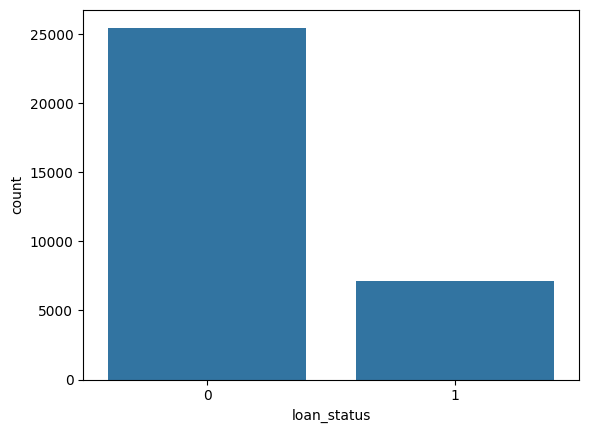

In [14]:
sns.countplot(x='loan_status', data=df)

In [15]:
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


In [16]:
numerical_cols = df.select_dtypes(include = np.number).columns
numerical_cols

Index(['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
       'loan_int_rate', 'loan_status', 'loan_percent_income',
       'cb_person_cred_hist_length'],
      dtype='object')

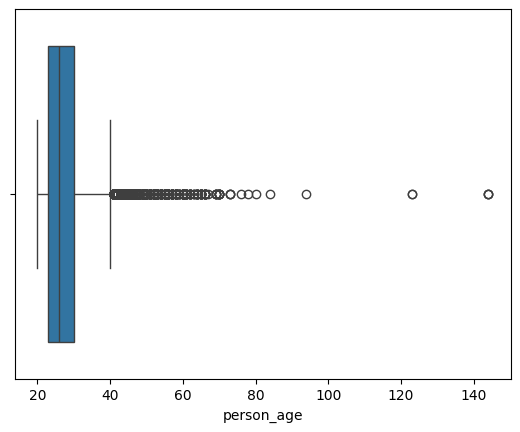

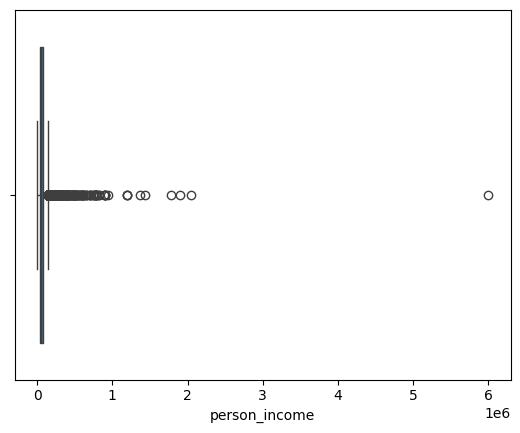

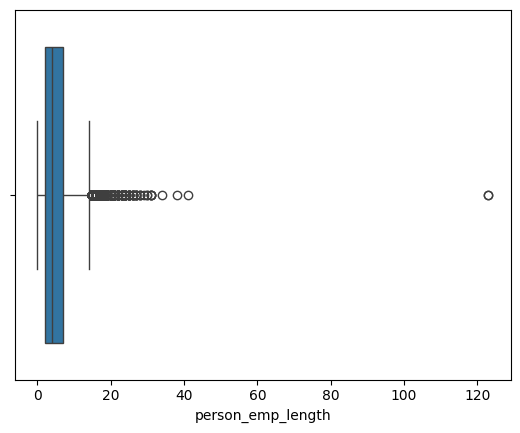

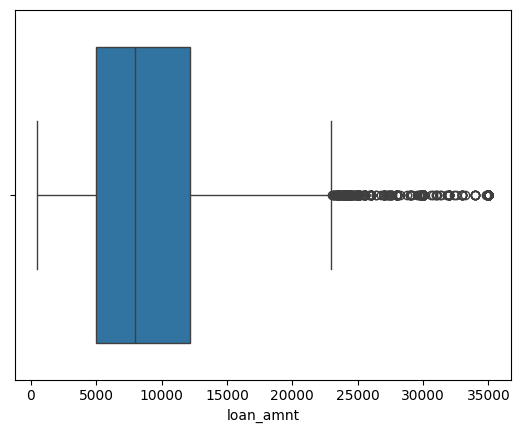

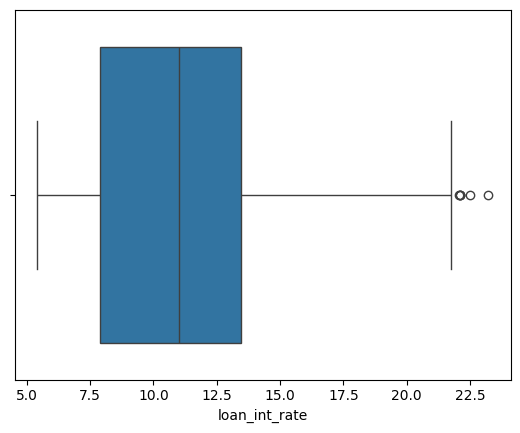

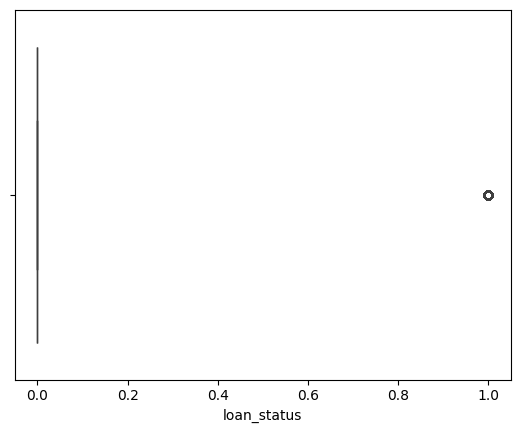

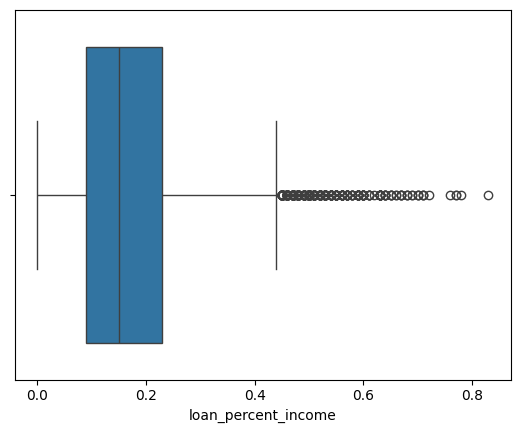

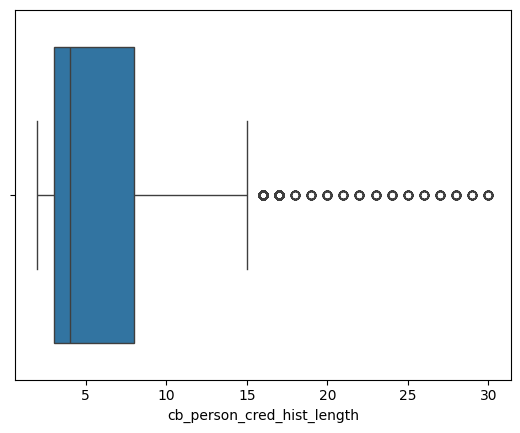

In [17]:
for i in numerical_cols:
  sns.boxplot(x=df[i])
  plt.show()

In [18]:
(df['person_age'] > 100).sum()

np.int64(5)

In [19]:
(df['person_emp_length'] > 60).sum()

np.int64(2)

<Axes: >

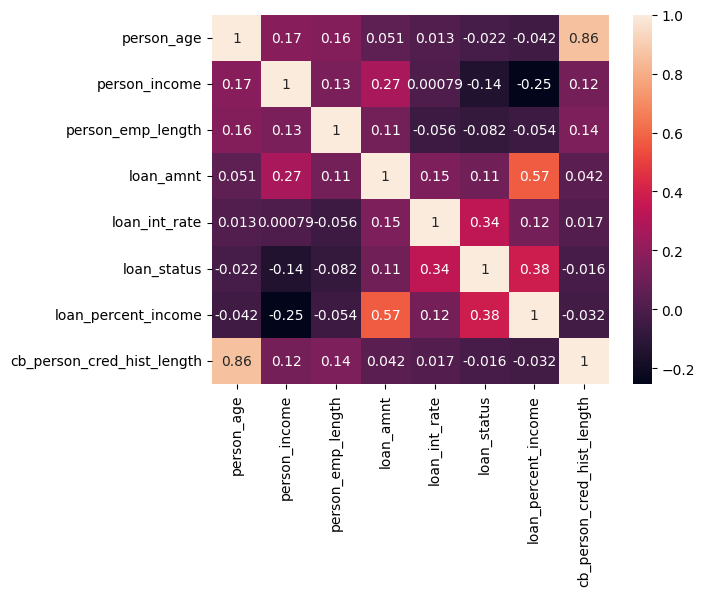

In [20]:
sns.heatmap(df.corr(numeric_only=True), annot=True)

# **Data Cleaning and Preprocessing**

In [21]:
df_copy = df.copy()

In [22]:
# Remove duplicate rows
df_copy.drop_duplicates(inplace=True)
df_copy.shape[0]

# Remove ages below 18 and above 100
df_copy = df_copy[df_copy['person_age']>=18]
df_copy = df_copy[df_copy['person_age']<=100]

# Remove employment length greater than age oe extreme outliers
df_copy = df_copy[df_copy['person_emp_length']<=df_copy['person_age']]
df_copy = df_copy[df_copy['person_emp_length']<=60]

# Remove the rows with zero or negative income and loan amount
df_copy = df_copy[df_copy['loan_amnt'] > 0]

In [23]:
df_copy.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,31522.000000,3.152200e+04,31522.000000,31522.000000,28495.000000,31522.000000,31522.000000,31522.000000
mean,27.742529,6.650168e+04,4.782850,9663.771334,11.045220,0.215944,0.169658,5.816097
std,6.218713,5.275216e+04,4.037343,6334.787700,3.230786,0.411482,0.106296,4.063622
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.943800e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.600000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,8.000000e+04,7.000000,12500.000000,13.480000,0.000000,0.230000,8.000000
max,94.000000,2.039784e+06,41.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


# **Features,Target & Train Test Split**

In [24]:
X = df_copy.drop('loan_status', axis=1)
y = df_copy['loan_status']

In [25]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [26]:
numeric_cols = ['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
       'loan_int_rate', 'loan_status', 'loan_percent_income',
       'cb_person_cred_hist_length']
categorical_cols = ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']

# **Handle Class Imbalance**

In [27]:
# Class - Weights

neg, pos = np.bincount(y_train)
scale_weights = neg/pos

# **Pipeline & Column Transformer**

In [28]:
# Logistic Regression : impute + SCALE Numeric, impute + One-Hot Encoding
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

preprocessor_lr = ColumnTransformer(
    transformers=[
        #Pipeline for numerical columns
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), numeric_cols),
        #Pipeline for categorical columns
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
            ('onehot', OneHotEncoder(handle_unknown='ignore'))
        ]), categorical_cols)
    ]
)

In [29]:
# XG Boost : impute numeric only (No scaling),impute + One-Hot Encoding

preprocessor_xg = ColumnTransformer(
    transformers=[
        #Pipeline for numerical columns
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median'))
        ]), numeric_cols),
        #Pipeline for categorical columns
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
            ('onehot', OneHotEncoder(handle_unknown='ignore'))
        ]), categorical_cols)
    ]
)

# **Evaluation Helper Function**

In [30]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, precision_recall_curve, classification_report
def evaluate_model(model_name, model, X_test, y_test, threshold=None):
    y_pred = model.predict(X_test)
    y_pred_prob = model.predict_proba(X_test)[:, 1]

    if threshold:
      y_pred = (y_pred_prob > threshold).astype(int)
    else:
      y_pred = model.predict(X_test)

    # Metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_pred_prob)

    cm = confusion_matrix(y_test, y_pred)
    class_report = classification_report(y_test, y_pred)

    print(f"Best Threshold: {best_threshold}")
    print(f"Accuracy: {accuracy:.2f}")
    print(f"Precision: {precision:.2f}")
    print(f"Recall: {recall:.2f}")
    print(f"F1 Score: {f1:.2f}")
    print(f"ROC AUC: {roc_auc:.2f}")
    print(f"{model_name} Classification Report:")
    print(class_report)

    # Plotting confusion matrix
    sns.heatmap(cm, annot=True, fmt='d')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title(f"{model_name} Confusion Matrix")
    plt.show()

    # Plotting ROC-AUC curve
    precisions, recalls, threshold = precision_recall_curve(y_test, y_pred_prob)
    plt.plot(recalls, precisions, label=f"{model_name} Precision-Recall Curve")
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title(f"{model_name} Precision-Recall Curve")
    plt.show()

# **Stratified Cross Validation**

In [31]:
from sklearn.model_selection import StratifiedKFold, cross_validate
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = {'roc_auc':'roc_auc', 'accuracy':'accuracy', 'precision':'precision', 'recall':'recall', 'f1':'f1'}

In [32]:
# Logistic Regression
from sklearn.linear_model import LogisticRegression
lr_cv_pipeline = Pipeline([
    ('preprocessor', preprocessor_lr),
    ('classifier', LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42))
])
lr_cv_pipeline

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_status',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['person_home_ownership',
                                                   'loan_intent', 'loan_grade',
                                                   'cb_person_default_on_file'])])),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])

In [33]:
#XG Boost
from xgboost import XGBClassifier
xg_cv_pipeline = Pipeline([
    ('preprocessor', preprocessor_xg),
    ('classifier', XGBClassifier(n_estimator=300, max_depth=5, learning_rate=0.1, scale_pos_weight=scale_weights, random_state=42))
])
xg_cv_pipeline

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_status',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 st...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=5, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimator=300, n_estimators=None, n_jobs=None, ...))])

In [34]:
# Remove loan_status from numeric_cols as it is our target variable
numeric_cols = [col for col in numeric_cols if col != 'loan_status']

# Redefine the Column Transformers with the updated numeric_cols
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.model_selection import cross_validate

preprocessor_lr = ColumnTransformer(
    transformers=[
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), numeric_cols),
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
            ('onehot', OneHotEncoder(handle_unknown='ignore'))
        ]), categorical_cols)
    ]
)

preprocessor_xg = ColumnTransformer(
    transformers=[
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median'))
        ]), numeric_cols),
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
            ('onehot', OneHotEncoder(handle_unknown='ignore'))
        ]), categorical_cols)
    ]
)

# Redefine pipelines (fixing 'n_estimators' typo in XGBClassifier)
lr_cv_pipeline = Pipeline([
    ('preprocessor', preprocessor_lr),
    ('classifier', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42))
])

xg_cv_pipeline = Pipeline([
    ('preprocessor', preprocessor_xg),
    ('classifier', XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.1, scale_pos_weight=scale_weights, random_state=42))
])

# Run Stratified Cross Validation
for cv_name, pipe in [('Logistic Regression', lr_cv_pipeline), ('XGBoost', xg_cv_pipeline)]:
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    print(f"=== {cv_name} ===")
    for metric in scoring.keys():
        mean_score = np.mean(scores[f'test_{metric}'])
        print(f"{metric}: {mean_score:.4f}")
    print()

=== Logistic Regression ===
roc_auc: 0.8705
accuracy: 0.8116
precision: 0.5448
recall: 0.7781
f1: 0.6408

=== XGBoost ===
roc_auc: 0.9471
accuracy: 0.9180
precision: 0.8191
recall: 0.7963
f1: 0.8073



# **Baseline Model**

In [35]:
baseline_model = Pipeline([
    ('Preprocessor', preprocessor_lr),
    ('Classifier', LogisticRegression(class_weight='balanced'))
])
baseline_model.fit(X_train, y_train)

Pipeline(steps=[('Preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['person_home_ownership',
                                                   'loan_intent', 'loan_grade',
                                                   'cb_person_default_on_file'])])),
                ('Classifier', LogisticRegression(class_weight='balanced'))])

In [36]:
y_pred = baseline_model.predict(X_test)

# **XG Boost Hyperparameter Tuning**

In [37]:
xg_model = Pipeline([
    ('preprocessor', preprocessor_xg),
    ('classifier', XGBClassifier(learning_rate=0.1, scale_pos_weights=scale_weights, random_state=42))
])
xg_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='consta...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=None, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=None, n_jobs=None,
                               num_parallel_tree=None, ...))])

Best Threshold: 0.4608519673347473
Accuracy: 0.82
Precision: 0.56
Recall: 0.79
F1 Score: 0.65
ROC AUC: 0.88
Logistic Regression Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.83      0.88      4943
           1       0.56      0.79      0.65      1362

    accuracy                           0.82      6305
   macro avg       0.75      0.81      0.77      6305
weighted avg       0.85      0.82      0.83      6305



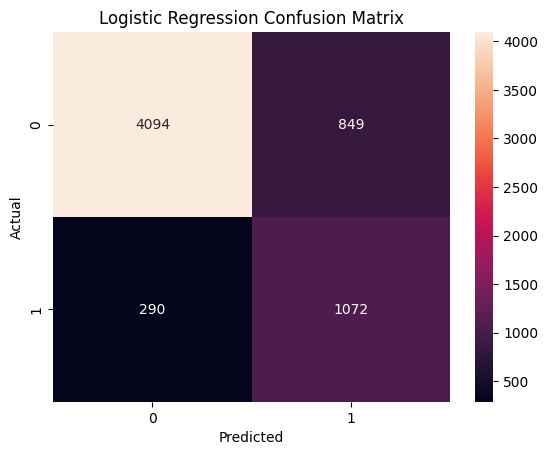

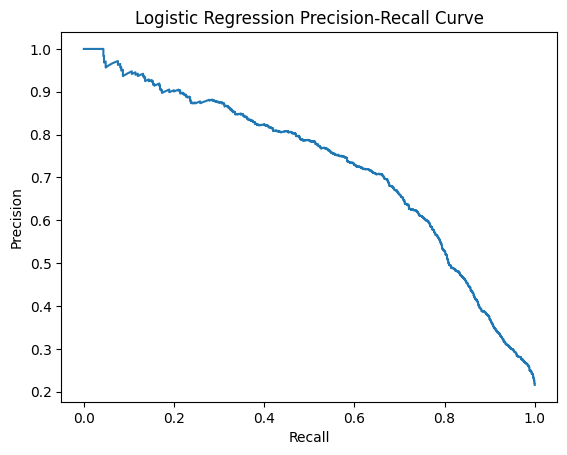

In [49]:
# Evaluate the Logistics Regression function
evaluate_model("Logistic Regression", baseline_model, X_test, y_test)

Best Threshold: 0.4608519673347473
Accuracy: 0.94
Precision: 0.97
Recall: 0.73
F1 Score: 0.83
ROC AUC: 0.95
XGBoost Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.99      0.96      4943
           1       0.97      0.73      0.83      1362

    accuracy                           0.94      6305
   macro avg       0.95      0.86      0.90      6305
weighted avg       0.94      0.94      0.93      6305



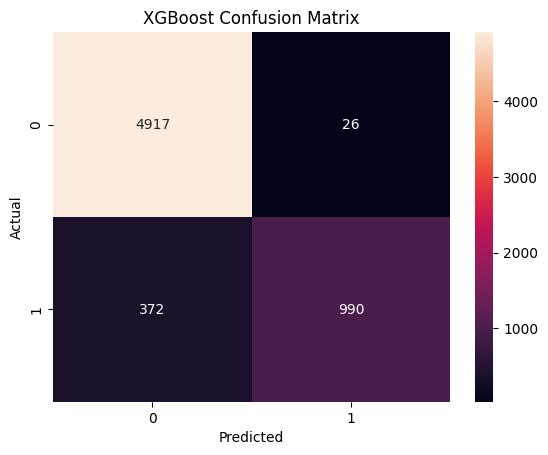

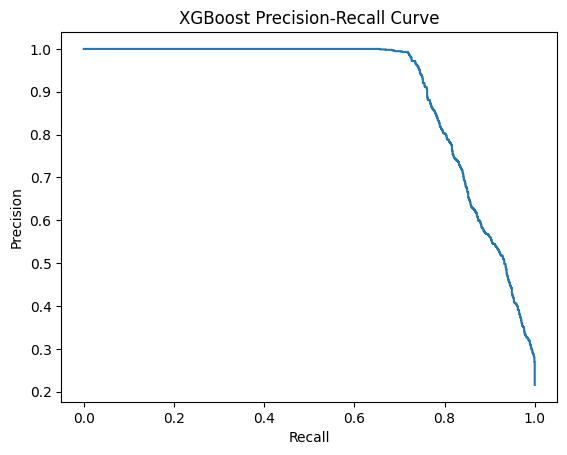

In [48]:
evaluate_model("XGBoost", xg_model, X_test, y_test)

# **XG Boost Hyperparameter Tuning**

In [39]:
from scipy.stats import uniform, randint
from sklearn.model_selection import RandomizedSearchCV

param_grid = {
    "classifier__n_estimators": randint(150, 600),
    "classifier__max_depth": randint(3, 9),
    "classifier__learning_rate": uniform(0.01, 0.5),
    "classifier__subsample": uniform(0.6, 0.4),#rows sampling
    "classifier__colsample_bytree": uniform(0.6, 0.4),#column sampling
    "classifier__min_child_weight": randint(1, 10),
    "classifier__gamma": uniform(0, 5)
}

In [40]:
random_search = RandomizedSearchCV(
    xg_model,
    param_grid,
    n_iter=150,
    cv=cv,
    scoring="average_precision",
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train, y_train)

Fitting 5 folds for each of 150 candidates, totalling 750 fits


RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('num',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer(strategy='median'))]),
                                                                               ['person_age',
                                                                                'person_income',
                                                                                'person_emp_length',
                                                                                'loan_amnt',
                                                                                'loan_int_rate',
                                                                                'loan_percent_income',
                                                                                'cb_person_cred_hist_length...
                                        'classifier__min_child_weight': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7afcb4f76fd0>,
                                        'classifier__n_estimators': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7afcb4f512b0>,
                                        'classifier__subsample': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x7afcb4f75f90>},
                   scoring='average_precision', verbose=1)

In [42]:
print(f"Score after performing tuning {random_search.best_score_:.2f}")

Score after performing tuning 0.90


# **Side by Side Comparison**

Best Threshold: 0.4608519673347473
Accuracy: 0.82
Precision: 0.56
Recall: 0.79
F1 Score: 0.65
ROC AUC: 0.88
Logistic Regression Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.83      0.88      4943
           1       0.56      0.79      0.65      1362

    accuracy                           0.82      6305
   macro avg       0.75      0.81      0.77      6305
weighted avg       0.85      0.82      0.83      6305



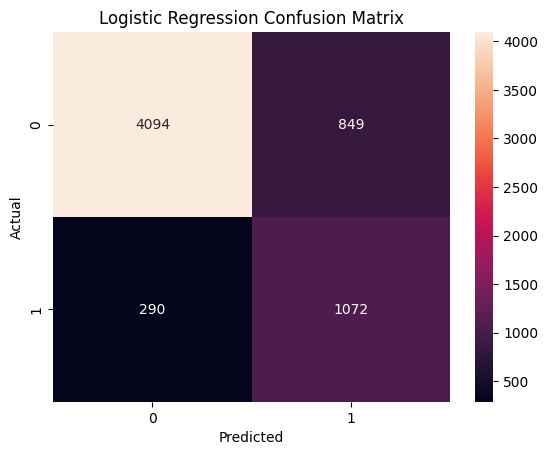

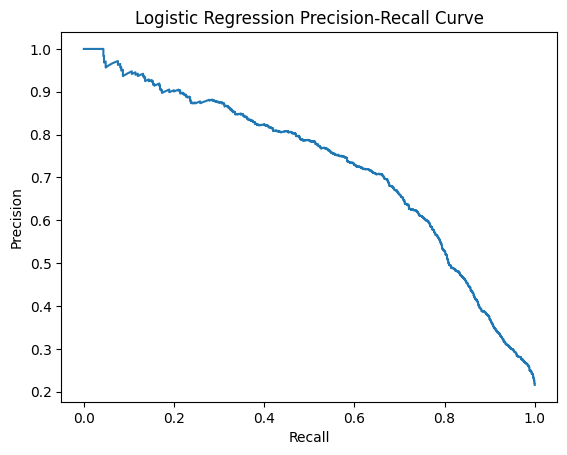

In [47]:
evaluate_model("Logistic Regression", baseline_model, X_test, y_test)

Best Threshold: 0.4608519673347473
Accuracy: 0.94
Precision: 0.94
Recall: 0.75
F1 Score: 0.84
ROC AUC: 0.95
XGBoost Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.99      0.96      4943
           1       0.94      0.75      0.84      1362

    accuracy                           0.94      6305
   macro avg       0.94      0.87      0.90      6305
weighted avg       0.94      0.94      0.93      6305



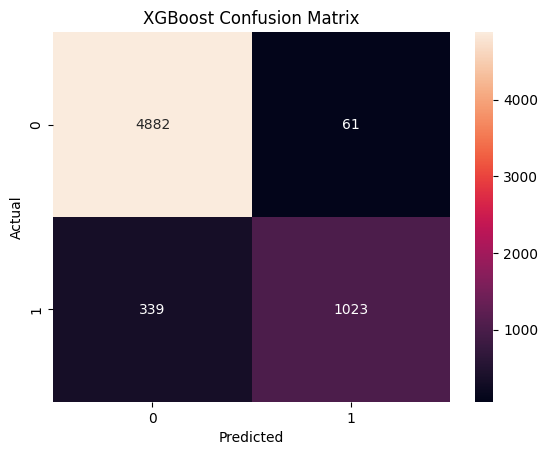

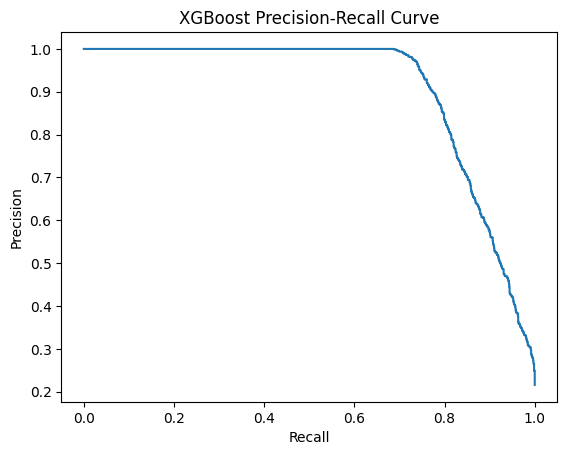

In [46]:
evaluate_model("XGBoost", random_search, X_test, y_test)

# **Optimizing Threshold**

Best Threshold: 0.4608519673347473
Accuracy: 0.94
Precision: 0.97
Recall: 0.73
F1 Score: 0.84
ROC AUC: 0.95
XGBoost Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.99      0.96      4943
           1       0.97      0.73      0.84      1362

    accuracy                           0.94      6305
   macro avg       0.95      0.86      0.90      6305
weighted avg       0.94      0.94      0.93      6305



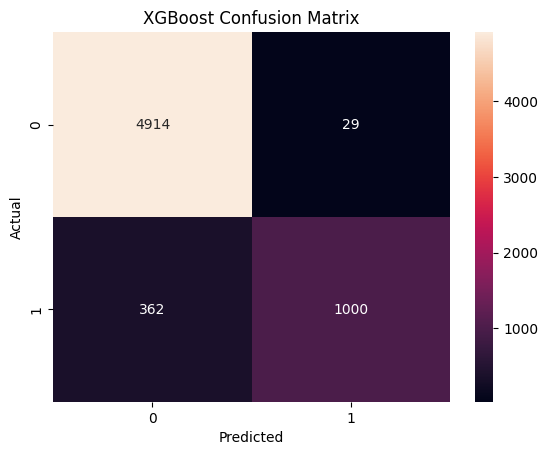

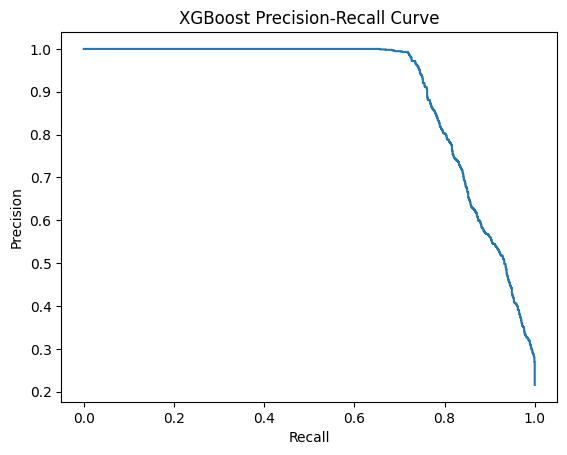

In [45]:
# Get the probability of class 1 from XGBoost
prob = xg_model.predict_proba(X_test)[:, 1]

# For each threshold calculate precision and recall
precisions, recalls, thresholds = precision_recall_curve(y_test, prob)

# Calculate F1 score for each threshold
f1 = 2 * (precisions * recalls) / (precisions + recalls + 1e-9)

# Find the threshold that produces the highest F1 score
best = np.argmax(f1[:-1])
best_threshold = thresholds[best]

# Evaluate the XGBoost model using that threshold
evaluate_model("XGBoost", xg_model, X_test, y_test, best_threshold)


# **Probability Calibration**

In [50]:
"""
Methods by which we an fix a poorly calibrated model are as follows:
1. Platt Scaling -> Adjust the probabilities using a sigmoid curve
2. Isotonic Regression -> Learn a flexible mapping from old prob. - better prob. (non-linear calibration)
3. Temperature Scaling -> Adjust the confidence of neural network predictions using one temperature
"""

'\nMethods by which we an fix a poorly calibrated model are as follows:\n1. Platt Scaling -> Adjust the probabilities using a sigmoid curve\n2. Isotonic Regression -> Learn a flexible mapping from old prob. - better prob. (non-linear calibration)\n3. Temperature Scaling -> Adjust the confidence of neural network predictions using one temperature\n'

In [73]:
# 1. Calibrate XGBoost Model
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
best_model = random_search.best_estimator_
calibrated_model = CalibratedClassifierCV(
    best_model,
    method='sigmoid',
    cv=5
)
calibrated_model.fit(X_train, y_train)

CalibratedClassifierCV(cv=5,
                       estimator=Pipeline(steps=[('preprocessor',
                                                  ColumnTransformer(transformers=[('num',
                                                                                   Pipeline(steps=[('imputer',
                                                                                                    SimpleImputer(strategy='median'))]),
                                                                                   ['person_age',
                                                                                    'person_income',
                                                                                    'person_emp_length',
                                                                                    'loan_amnt',
                                                                                    'loan_int_rate',
                                                                                    'loan_percent_income',
                                                                                    'cb_person_cred_hist_length']),
                                                                                  ('cat',
                                                                                   Pipeline(steps=[('imputer',
                                                                                                    SimpleImputer...
                                                                grow_policy=None,
                                                                importance_type=None,
                                                                interaction_constraints=None,
                                                                learning_rate=np.float64(0.4208605207247722),
                                                                max_bin=None,
                                                                max_cat_threshold=None,
                                                                max_cat_to_onehot=None,
                                                                max_delta_step=None,
                                                                max_depth=5,
                                                                max_leaves=None,
                                                                min_child_weight=1,
                                                                missing=nan,
                                                                monotone_constraints=None,
                                                                multi_strategy=None,
                                                                n_estimators=545,
                                                                n_jobs=None,
                                                                num_parallel_tree=None, ...))]))

In [74]:
# 2. Get probabilities
uncalibrated = xg_model.predict_proba(X_test)[:, 1]
calibrated = calibrated_model.predict_proba(X_test)[:, 1]

In [75]:
uncalibrated

array([0.8499355 , 0.07363087, 0.94845796, ..., 0.20415357, 0.02698087,
       0.01797598], dtype=float32)

In [76]:
calibrated

array([0.75430377, 0.04141622, 0.9779303 , ..., 0.25197129, 0.0380089 ,
       0.03323394])

In [77]:
# 3. Create calibration curves
actual_uncalib, predicted_uncalib = calibration_curve(y_test, uncalibrated, n_bins=10)
actual_calib, predicted_calib = calibration_curve(y_test, calibrated, n_bins=10)

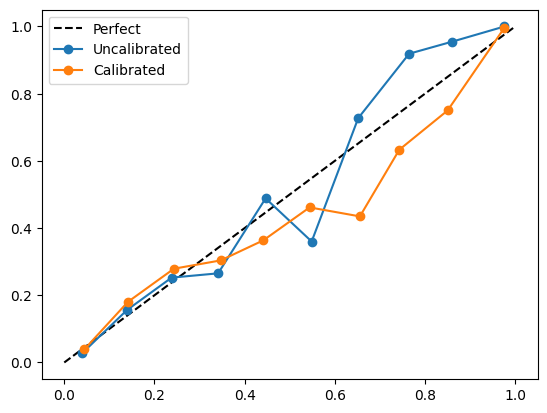

In [78]:
# 4. Plot
plt.plot([0,1], [0,1], 'k--', label="Perfect")
plt.plot(
    predicted_uncalib,
    actual_uncalib,
    "o-",
    label='Uncalibrated'
)

plt.plot(
    predicted_calib,
    actual_calib,
    "o-",
    label='Calibrated'
)

plt.legend()

# **SHAP Interpretation**

In [79]:
#1. Install SHAP if not exists
!pip install shap
import shap

In [80]:
#2. Get the trained XGBoost classifier model out of the pipeline
xg_classifier = xg_model.named_steps['classifier']

In [82]:
#3. Transform X_test using the same preprocessing used for training
X_test_transformed = xg_model.named_steps['preprocessor'].transform(X_test)

In [83]:
#4. Get feature names after one-hot encoding, so plots are readable
feature_names = xg_model.named_steps['preprocessor'].get_feature_names_out()

In [84]:
#5. Convert to a dataframe for cleaner SHAP plots
X_test_df = pd.DataFrame(X_test_transformed, columns=feature_names)

In [85]:
#6. Create SHAP explainer built for tree-based model
explainer = shap.TreeExplainer(xg_classifier)

In [86]:
 #7. Calculate SHAP values for every row in the test set
 shap_values = explainer.shap_values(X_test_df)
 shap_values

array([[-5.6159213e-02,  8.0936946e-02,  2.3971802e-01, ...,
        -6.3014673e-03, -8.5162811e-02,  0.0000000e+00],
       [ 1.0625595e-01, -8.2727873e-01, -6.3003510e-02, ...,
        -9.5448568e-03, -1.1467045e-02,  0.0000000e+00],
       [ 8.4587336e-02,  4.0324259e+00,  1.7046891e-01, ...,
        -6.5198136e-03, -3.9520292e-03,  0.0000000e+00],
       ...,
       [-1.7128091e-02,  6.6334897e-01,  6.6646114e-02, ...,
        -8.6026313e-03, -1.6487224e-02,  0.0000000e+00],
       [-7.4319285e-04, -8.5076767e-01,  2.9672325e-02, ...,
        -9.0121748e-03, -1.7108688e-02,  0.0000000e+00],
       [-1.1183254e-01, -4.3285662e-01,  4.7062483e-02, ...,
        -8.2185566e-03, -1.6994895e-02,  0.0000000e+00]], dtype=float32)

# **Global Explanation**

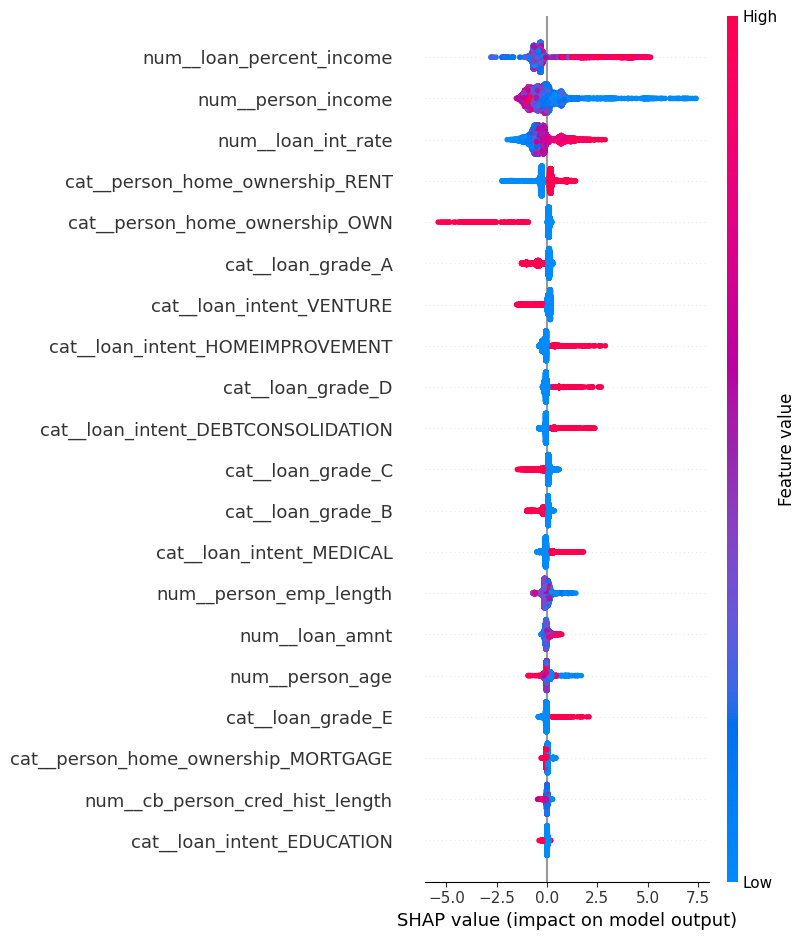

In [87]:
shap.summary_plot(shap_values, X_test_df)

# **Local Explanation**

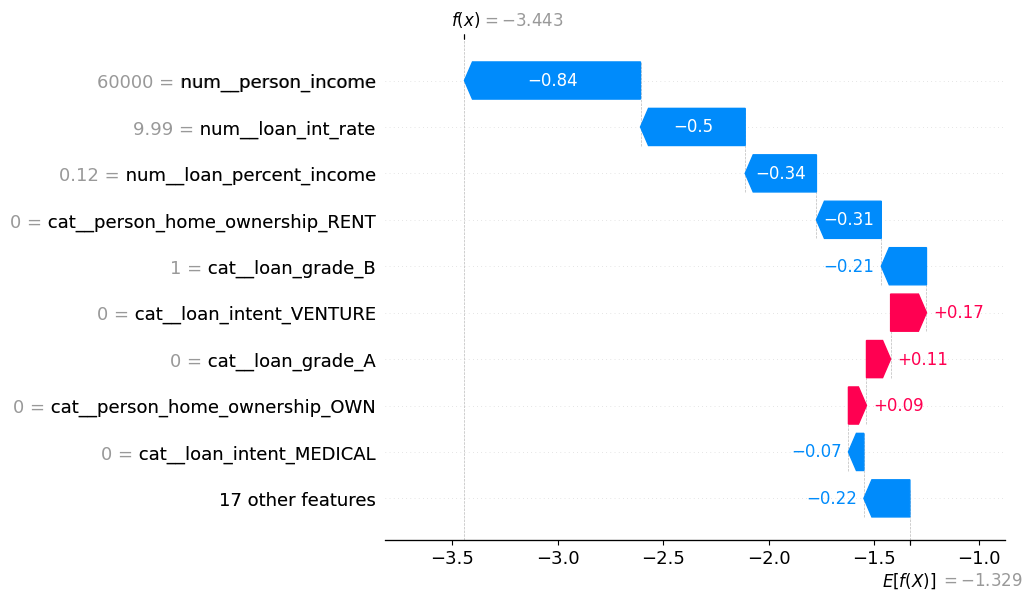

In [88]:
#1. Pick one row to explain, e.g the 5th applicant in the test set.
row_index = 5

#2. Draw a waterfall plot showing how each feature pushed the prediction up or down
shap.plots.waterfall(
    shap.Explanation(
        values = shap_values [row_index],
        base_values = explainer.expected_value,
        data = X_test_df.iloc[row_index],
        feature_names = feature_names
    )
)

# **Analzing False Positives and False Negatives**

In [89]:
# Get predictions from best performing XGBoost Model on the test set
y_pred = random_search.predict(X_test)

In [90]:
# Create a dataframe to easily compare actual and predicted values
result_df = X_test.copy()

In [91]:
result_df['actual'] = y_test
result_df['predicted'] = y_pred

In [92]:
# Identify False positives: Model predicted 1 but the actual was 0
false_positive = result_df[(result_df['predicted'] == 1) & (result_df['actual'] == 0)]

# Identify False negatives: Model predicted 0 but the actual was 1
false_negative = result_df[(result_df['predicted'] == 0) & (result_df['actual'] == 1)]

In [93]:
print(f"False Positives: {len(false_positive)}")
print(f"False Negatives: {len(false_negative)}")

False Positives: 61
False Negatives: 339


# **Save the final model**

In [94]:
import joblib
joblib.dump(calibrated_model, "credit_risk_model.pkl")

['credit_risk_model.pkl']

In [95]:
joblib.dump(best_threshold, "best_threshold.pkl")

['best_threshold.pkl']

# **Optimizing Threshold Correction**

In [96]:
from sklearn.metrics import precision_recall_curve
import numpy as np

# Get probabilities from calibrated model
calibrated_proba = calibrated_model.predict_proba(X_test)[:, 1]

precisions, recalls, thresholds = precision_recall_curve(y_test, calibrated_proba)

# Calculate F1 score for each threshold
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-9)

# Find the threshold that produces the highest F1 score
best_threshold = thresholds[np.argmax(f1_scores[:-1])]

print(f"New Threshold: {best_threshold}")

New Threshold: 0.5065006244331733


In [97]:
joblib.dump(best_threshold, "best_threshold.pkl")

['best_threshold.pkl']